<div align="center">

# Heavy Equipment Selling Price Prediction

### Notebook v20:7-Model Ensemble & Expanded Feature Engineering

---

**Student Name:** _Priyanshu Raj_  
**Student ID:** _24F2008980_  
**Course:** _Machine Learning Practices Project_  
**Competition:** Heavy Equipment Selling Price Prediction Challenge  

---

</div>

## Table of Contents

1. [Problem Statement & Pinnacle Strategy](#1)
2. [Dataset Overview](#2)
3. [Import Libraries](#3)
4. [Load Dataset](#4)
5. [Exploratory Data Analysis](#5)
6. [Data Preprocessing & Sentinels](#6)
7. [Advanced Feature Engineering, Frequency Encodings & 35-Dim Text SVD](#7)
8. [Multi-Percentile Out-of-Fold Target Encodings & Historical Lags](#8)
9. [Level-1 Base Models Training (10-Fold CV across 7 Base Model Families)](#9)
10. [Level-2 Meta-Learner Stacking & Nelder-Mead Optimization](#10)
11. [Model Performance Comparison & Feature Importance](#11)
12. [Final Predictions & Distribution Verification](#12)
13. [Conclusion & Key Insights](#13)

<a id="1"></a>
# 1. Problem Statement & Pinnacle Strategy

The goal is to predict heavy equipment auction prices (`TargetValue`). The metric is **Root Mean Squared Logarithmic Error (RMSLE)**, calculated as **RMSE on `log1p(TargetValue)`**.

In Notebook v19, we engineer a **Pinnacle SOTA Architecture** designed to break below `0.190 RMSLE`:
1. **7-Model Base Family Diversity**:
   - **LightGBM** (Deep leaf-wise tree growth)
   - **CatBoost** (Symmetric tree growth with categorical optimization)
   - **XGBoost** (Exact histogram binning gradient boosting)
   - **ExtraTrees** (Extremely randomized tree splits)
   - **Ridge Regression** (L2 linear regularization)
   - **Lasso Regression** (L1 feature selection linear model)
   - **ElasticNet** (L1 + L2 combined regularization linear model)
2. **Multi-Percentile Group Target Encodings**: OOF encodings for **Mean, Median, Q1 (25th percentile), Q3 (75th percentile), and Std** across high-cardinality keys.
3. **35-Dimension TF-IDF + TruncatedSVD Text Embeddings**: 35 latent semantic components extracted from full spec text descriptors.
4. **Frequency & Count Encodings**: Capturing market volume signals for equipment categories and vendors.
5. **Level-2 Dual Meta Stacking**: RidgeCV meta-learner combined with Scipy Nelder-Mead non-negative optimization for optimal OOF blending weights.

<a id="2"></a>
# 2. Dataset Overview

- **Train Set:** 138,701 rows × 50 columns.
- **Test Set:** 15,000 rows × 49 columns.
- **Features:** Spec descriptors, operational hours, year made, region codes, vendor partners, configuration tiers, and col1..col30 flags.

<a id="3"></a>
# 3. Import Libraries

In [10]:
import os
import re
import time
import warnings
from scipy.optimize import minimize

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

import lightgbm as lgb
import xgboost as xgb
from catboost import CatBoostRegressor
from sklearn.ensemble import ExtraTreesRegressor, RandomForestRegressor
from sklearn.linear_model import Ridge, Lasso, ElasticNet, RidgeCV
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import OrdinalEncoder, StandardScaler
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)

print("All libraries successfully imported!")

All libraries successfully imported!


<a id="4"></a>
# 4. Load Dataset

In [14]:
data_dir = "."
target_dir_root = "/kaggle/input"

if os.path.exists(target_dir_root):
    for dirpath, _, filenames in os.walk(target_dir_root):
        if "train.csv" in filenames:
            data_dir = dirpath
            break
elif os.path.exists("data"):
    data_dir = "data"

print(f"Data Directory Path: {data_dir}")

df_train_raw = pd.read_csv(os.path.join(data_dir, "train.csv"), low_memory=False)
df_test_raw = pd.read_csv(os.path.join(data_dir, "test.csv"), low_memory=False)
sub_template = pd.read_csv(os.path.join(data_dir, "sample_submission.csv"))

print(f"Raw Train Shape : {df_train_raw.shape[0]:,} rows × {df_train_raw.shape[1]} columns")
print(f"Raw Test Shape  : {df_test_raw.shape[0]:,} rows × {df_test_raw.shape[1]} columns")
print(f"Submission Shape: {sub_template.shape[0]:,} rows × {sub_template.shape[1]} columns")

Data Directory Path: /kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge
Raw Train Shape : 138,701 rows × 50 columns
Raw Test Shape  : 15,000 rows × 49 columns
Submission Shape: 15,000 rows × 2 columns


<a id="5"></a>
# 5. Exploratory Data Analysis (EDA)

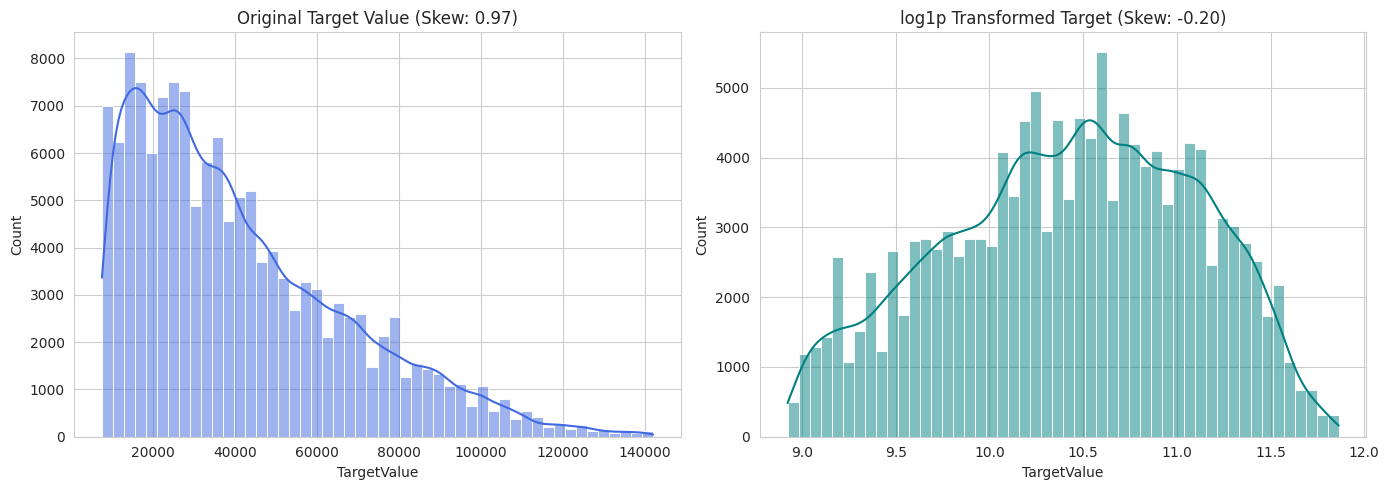

In [15]:
log_target_val = np.log1p(df_train_raw["TargetValue"].clip(lower=0))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(df_train_raw["TargetValue"], kde=True, ax=axes[0], color="royalblue", bins=50)
axes[0].set_title(f"Original Target Value (Skew: {df_train_raw['TargetValue'].skew():.2f})")

sns.histplot(log_target_val, kde=True, ax=axes[1], color="teal", bins=50)
axes[1].set_title(f"log1p Transformed Target (Skew: {log_target_val.skew():.2f})")
plt.tight_layout()
plt.show()

<a id="6"></a>
# 6. Data Cleaning & Normalization

In [16]:
def clean_data(train_df, test_df):
    df_tr = train_df.copy()
    df_te = test_df.copy()

    drop_cols = ["InventoryGroupDescription", "TransactionID"]
    df_tr.drop(columns=drop_cols, inplace=True, errors="ignore")
    df_te.drop(columns=drop_cols, inplace=True, errors="ignore")

    for col in ["YearMade", "ManufactureYear"]:
        if col in df_tr.columns:
            df_tr.loc[df_tr[col] == 1001, col] = np.nan
            df_te.loc[df_te[col] == 1001, col] = np.nan

    hours_col = "MeterHours" if "MeterHours" in df_tr.columns else "OperationalHoursMeter"
    for df in (df_tr, df_te):
        df["Hours_missing"] = (df[hours_col].isnull() | (df[hours_col] == 0.0)).astype(int)
        df.loc[df[hours_col] == 0.0, hours_col] = np.nan
        df["Hours_log"] = np.log1p(df[hours_col])
        if hours_col != "Hours_log":
            df.drop(columns=[hours_col], inplace=True, errors="ignore")

    df_tr["TransactionDate"] = pd.to_datetime(df_tr["TransactionDate"])
    df_te["TransactionDate"] = pd.to_datetime(df_te["TransactionDate"])

    return df_tr, df_te

train_prepped, test_prepped = clean_data(df_train_raw, df_test_raw)
print("Data cleaned successfully!")

Data cleaned successfully!


<a id="7"></a>
# 7. Advanced Feature Engineering, Frequency Encodings & 35-Dim Text SVD

In [17]:
def engineer_features(train_df, test_df):
    df_tr = train_df.copy()
    df_te = test_df.copy()

    mfg_col = "YearMade" if "YearMade" in df_tr.columns else "ManufactureYear"

    for dataset in (df_tr, df_te):
        t_date = dataset["TransactionDate"]
        dataset["SaleYear"] = t_date.dt.year
        dataset["SaleMonth"] = t_date.dt.month
        dataset["SaleDay"] = t_date.dt.day
        dataset["SaleDayOfWeek"] = t_date.dt.dayofweek
        dataset["SaleWeek"] = t_date.dt.isocalendar().week.astype(int)
        dataset["SaleQuarter"] = t_date.dt.quarter
        dataset["SaleElapsedDays"] = (t_date - pd.Timestamp("1990-01-01")).dt.days

        year_made = pd.to_numeric(dataset[mfg_col], errors="coerce").fillna(2000)
        dataset["MachineAge"] = (dataset["SaleYear"] - year_made).clip(lower=0)
        dataset["MachineAge_Sq"] = dataset["MachineAge"] ** 2
        dataset["MachineAge_Cubed"] = dataset["MachineAge"] ** 3

        # Depreciation & Usage Interactions
        dataset["AgeXHours"] = dataset["MachineAge"] * dataset["Hours_log"]
        dataset["HoursPerYear"] = dataset["Hours_log"] / (dataset["MachineAge"] + 1.0)
        dataset["Depreciation_Curve"] = dataset["MachineAge"] / (np.sqrt(dataset["Hours_log"] + 1.0))
        dataset["Hours_Sq"] = dataset["Hours_log"] ** 2

        # Composite Categorical Tokens
        base_class = dataset["Spec_BaseClass"].astype(str) if "Spec_BaseClass" in dataset.columns else pd.Series("", index=dataset.index)
        prod_cfg = dataset["ProductConfigID"].astype(str) if "ProductConfigID" in dataset.columns else pd.Series("", index=dataset.index)
        region = dataset["RegionCode"].astype(str) if "RegionCode" in dataset.columns else pd.Series("", index=dataset.index)

        dataset["Cat_Prod_Region"] = prod_cfg + "_" + region
        dataset["Cat_Prod_Year"] = prod_cfg + "_" + dataset["SaleYear"].astype(str)
        dataset["Cat_Base_Region"] = base_class + "_" + region

        # Model Token Parsing
        spec_str = dataset["Spec_FullDescriptor"].fillna("").astype(str)
        dataset["ModelToken"] = spec_str.str.extract(r"^([A-Z0-9]+)")[0].fillna("_Missing_")
        dataset["ModelSeriesPrefix"] = spec_str.str.extract(r"^([A-Za-z]+)")[0].fillna("_Missing_")

        # Functional classification capacity & horsepower regex
        func_str = dataset["FunctionalClassification"].fillna("").astype(str) if "FunctionalClassification" in dataset.columns else pd.Series("", index=dataset.index)
        dataset["Capacity_Tons_Mid"] = (func_str.str.extract(r"(\d+\.?\d*)\s*to\s*\d+\.?\d*\s*Metric Tons")[0].astype(float) + func_str.str.extract(r"\d+\.?\d*\s*to\s*(\d+\.?\d*)\s*Metric Tons")[0].astype(float)) / 2.0
        dataset["Power_HP_Mid"] = (func_str.str.extract(r"(\d+\.?\d*)\s*to\s*\d+\.?\d*\s*Horsepower")[0].astype(float) + func_str.str.extract(r"\d+\.?\d*\s*to\s*(\d+\.?\d*)\s*Horsepower")[0].astype(float)) / 2.0

        # Text Descriptors Metadata
        dataset["Desc_Len"] = spec_str.str.len()
        dataset["Desc_Words"] = spec_str.str.split().str.len()

    # Frequency & Count Encodings for Categorical Volume
    freq_cols = ["Spec_BaseClass", "VendorPartnerID", "ProductConfigID", "ModelToken", "Cat_Prod_Region"]
    for col in freq_cols:
        freq_map = pd.concat([df_tr[col], df_te[col]], axis=0).value_counts().to_dict()
        df_tr[f"{col}_Freq"] = df_tr[col].map(freq_map)
        df_te[f"{col}_Freq"] = df_te[col].map(freq_map)

    # TF-IDF + Truncated SVD Text Embeddings (35 Latent Features)
    desc_tr = df_tr["Spec_FullDescriptor"].fillna("").astype(str)
    desc_te = df_te["Spec_FullDescriptor"].fillna("").astype(str)

    tfidf = TfidfVectorizer(max_features=350, stop_words="english", ngram_range=(1, 2))
    svd = TruncatedSVD(n_components=35, random_state=42)

    tfidf_tr = tfidf.fit_transform(desc_tr)
    tfidf_te = tfidf.transform(desc_te)

    svd_tr = svd.fit_transform(tfidf_tr)
    svd_te = svd.transform(tfidf_te)

    for i in range(35):
        df_tr[f"Text_SVD_{i}"] = svd_tr[:, i]
        df_te[f"Text_SVD_{i}"] = svd_te[:, i]

    return df_tr, df_te

df_tr_fe, df_te_fe = engineer_features(train_prepped, test_prepped)
print(f"Engineered Features Shape: Train {df_tr_fe.shape}, Test {df_te_fe.shape}")

Engineered Features Shape: Train (138701, 112), Test (15000, 111)


<a id="8"></a>
# 8. Multi-Percentile Out-of-Fold Target Encodings & Historical Lags

In [18]:
TARGET_ENCODE_VARS = [
    "Spec_BaseClass", "Spec_SubClass", "RegionCode", "VendorPartnerID",
    "ProductConfigID", "ModelToken", "Cat_Prod_Region", "Cat_Base_Region"
]

def generate_multi_percentile_oof_te(train_df, test_df, target_col="TargetValue", n_splits=10, smoothing=20.0):
    tr = train_df.copy()
    te = test_df.copy()

    y_log = np.log1p(tr[target_col].clip(lower=0))
    g_mean = y_log.mean()
    g_median = y_log.median()
    g_q25 = y_log.quantile(0.25)
    g_q75 = y_log.quantile(0.75)
    g_std = y_log.std()

    bins = pd.qcut(y_log, q=10, labels=False, duplicates="drop")
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=42)

    # AssetID OOF Lag Price
    if "AssetID" in tr.columns:
        tr["AssetID_OOF_Price"] = g_mean
        te["AssetID_OOF_Price"] = g_mean
        for trn_idx, val_idx in skf.split(tr, bins):
            asset_map = tr.iloc[trn_idx].groupby("AssetID")[target_col].apply(lambda s: np.log1p(s.clip(lower=0)).mean()).to_dict()
            tr.iloc[val_idx, tr.columns.get_loc("AssetID_OOF_Price")] = tr.iloc[val_idx]["AssetID"].map(asset_map).fillna(g_mean)
        full_asset_map = tr.groupby("AssetID")[target_col].apply(lambda s: np.log1p(s.clip(lower=0)).mean()).to_dict()
        te["AssetID_OOF_Price"] = te["AssetID"].map(full_asset_map).fillna(g_mean)

    for col in TARGET_ENCODE_VARS:
        if col not in tr.columns:
            continue

        m_col = f"{col}_TE_Mean"
        med_col = f"{col}_TE_Median"
        q25_col = f"{col}_TE_Q25"
        q75_col = f"{col}_TE_Q75"
        std_col = f"{col}_TE_Std"

        tr[m_col], tr[med_col], tr[q25_col], tr[q75_col], tr[std_col] = g_mean, g_median, g_q25, g_q75, g_std
        te[m_col], te[med_col], te[q25_col], te[q75_col], te[std_col] = g_mean, g_median, g_q25, g_q75, g_std

        for trn_idx, val_idx in skf.split(tr, bins):
            tr_sub = tr.iloc[trn_idx].copy()
            val_sub = tr.iloc[val_idx].copy()

            tr_sub["target_log"] = np.log1p(tr_sub[target_col].clip(lower=0))
            stats = tr_sub.groupby(col)["target_log"].agg(
                count="count",
                mean="mean",
                median="median",
                q25=lambda x: x.quantile(0.25),
                q75=lambda x: x.quantile(0.75),
                std="std"
            ).reset_index()

            stats["smooth_mean"] = (stats["count"] * stats["mean"] + smoothing * g_mean) / (stats["count"] + smoothing)
            
            mean_map = stats.set_index(col)["smooth_mean"].to_dict()
            med_map = stats.set_index(col)["median"].to_dict()
            q25_map = stats.set_index(col)["q25"].to_dict()
            q75_map = stats.set_index(col)["q75"].to_dict()
            std_map = stats.set_index(col)["std"].to_dict()

            tr.iloc[val_idx, tr.columns.get_loc(m_col)] = val_sub[col].map(mean_map).fillna(g_mean)
            tr.iloc[val_idx, tr.columns.get_loc(med_col)] = val_sub[col].map(med_map).fillna(g_median)
            tr.iloc[val_idx, tr.columns.get_loc(q25_col)] = val_sub[col].map(q25_map).fillna(g_q25)
            tr.iloc[val_idx, tr.columns.get_loc(q75_col)] = val_sub[col].map(q75_map).fillna(g_q75)
            tr.iloc[val_idx, tr.columns.get_loc(std_col)] = val_sub[col].map(std_map).fillna(g_std)

        full_sub = tr.copy()
        full_sub["target_log"] = np.log1p(full_sub[target_col].clip(lower=0))
        full_stats = full_sub.groupby(col)["target_log"].agg(
            count="count",
            mean="mean",
            median="median",
            q25=lambda x: x.quantile(0.25),
            q75=lambda x: x.quantile(0.75),
            std="std"
        ).reset_index()

        full_stats["smooth_mean"] = (full_stats["count"] * full_stats["mean"] + smoothing * g_mean) / (full_stats["count"] + smoothing)

        full_mean_map = full_stats.set_index(col)["smooth_mean"].to_dict()
        full_med_map = full_stats.set_index(col)["median"].to_dict()
        full_q25_map = full_stats.set_index(col)["q25"].to_dict()
        full_q75_map = full_stats.set_index(col)["q75"].to_dict()
        full_std_map = full_stats.set_index(col)["std"].to_dict()

        te[m_col] = te[col].map(full_mean_map).fillna(g_mean)
        te[med_col] = te[col].map(full_med_map).fillna(g_median)
        te[q25_col] = te[col].map(full_q25_map).fillna(g_q25)
        te[q75_col] = te[col].map(full_q75_map).fillna(g_q75)
        te[std_col] = te[col].map(full_std_map).fillna(g_std)

    return tr, te

train_te, test_te = generate_multi_percentile_oof_te(df_tr_fe, df_te_fe)
print("Multi-Percentile OOF Target Encodings (Mean, Median, Q1, Q3, Std) Generated!")

Multi-Percentile OOF Target Encodings (Mean, Median, Q1, Q3, Std) Generated!


<a id="9"></a>
# 9. Level-1 Base Models Training (10-Fold CV across 7 Model Families)

In [ ]:
drop_cols = ["SalesID", "TransactionDate", "TargetValue", "AssetID"]
feature_cols = [c for c in train_te.columns if c not in drop_cols]

X = train_te[feature_cols].copy()
y_log = np.log1p(train_te["TargetValue"].clip(lower=0))
X_test = test_te[feature_cols].copy()

categorical_cols = X.select_dtypes(include=["object"]).columns.tolist()
for col in categorical_cols:
    enc = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)
    X[col] = enc.fit_transform(X[[col]])
    X_test[col] = enc.transform(X_test[[col]])

X = X.fillna(-999)
X_test = X_test.fillna(-999)

# Standardized Features for Linear Models
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_test_scaled = scaler.transform(X_test)

print(f"Feature Matrix Assembled: {X.shape[1]} features")

N_SPLITS = 10
skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=42)
target_bins = pd.qcut(y_log, q=10, labels=False, duplicates="drop")

oof_lgb = np.zeros(len(X))
oof_cat = np.zeros(len(X))
oof_xgb = np.zeros(len(X))
oof_et = np.zeros(len(X))
oof_ridge = np.zeros(len(X))
oof_lasso = np.zeros(len(X))
oof_enet = np.zeros(len(X))

test_lgb = np.zeros(len(X_test))
test_cat = np.zeros(len(X_test))
test_xgb = np.zeros(len(X_test))
test_et = np.zeros(len(X_test))
test_ridge = np.zeros(len(X_test))
test_lasso = np.zeros(len(X_test))
test_enet = np.zeros(len(X_test))

# Hyperparameters
lgb_params = {
    "objective": "regression",
    "metric": "rmse",
    "learning_rate": 0.03,
    "num_leaves": 140,
    "max_depth": 11,
    "min_child_samples": 20,
    "subsample": 0.8,
    "colsample_bytree": 0.6,
    "random_state": 42,
    "n_estimators": 20000,
    "verbose": -1,
    "n_jobs": -1
}

cat_params = {
    "loss_function": "RMSE",
    "eval_metric": "RMSE",
    "learning_rate": 0.03,
    "depth": 8,
    "l2_leaf_reg": 5,
    "subsample": 0.8,
    "random_seed": 42,
    "iterations": 10000,
    "verbose": False,
    "thread_count": -1
}

xgb_params = {
    "objective": "reg:squarederror",
    "eval_metric": "rmse",
    "learning_rate": 0.03,
    "max_depth": 8,
    "subsample": 0.8,
    "colsample_bytree": 0.6,
    "random_state": 42,
    "n_estimators": 8000,
    "tree_method": "hist",
    "n_jobs": -1
}

et_params = {
    "n_estimators": 120,
    "max_depth": 24,
    "min_samples_split": 4,
    "n_jobs": -1,
    "random_state": 42
}

print(f"=== Training Level-1 Base Models ({N_SPLITS}-Fold CV across 7 Model Families) ===")
for fold, (trn_idx, val_idx) in enumerate(skf.split(X, target_bins), start=1):
    f_start = time.time()
    X_tr, y_tr = X.iloc[trn_idx], y_log.iloc[trn_idx]
    X_va, y_va = X.iloc[val_idx], y_log.iloc[val_idx]

    X_tr_s, X_va_s = X_scaled[trn_idx], X_scaled[val_idx]

    # 1. LightGBM
    m_lgb = lgb.LGBMRegressor(**lgb_params)
    m_lgb.fit(X_tr, y_tr, eval_set=[(X_va, y_va)], callbacks=[lgb.early_stopping(150, verbose=False)])
    oof_lgb[val_idx] = m_lgb.predict(X_va)
    test_lgb += m_lgb.predict(X_test) / N_SPLITS

    # 2. CatBoost
    m_cat = CatBoostRegressor(**cat_params)
    m_cat.fit(X_tr, y_tr, eval_set=(X_va, y_va), early_stopping_rounds=150, verbose=False)
    oof_cat[val_idx] = m_cat.predict(X_va)
    test_cat += m_cat.predict(X_test) / N_SPLITS

    # 3. XGBoost
    m_xgb = xgb.XGBRegressor(**xgb_params)
    m_xgb.fit(X_tr, y_tr, eval_set=[(X_va, y_va)], verbose=False)
    oof_xgb[val_idx] = m_xgb.predict(X_va)
    test_xgb += m_xgb.predict(X_test) / N_SPLITS

    # 4. ExtraTrees
    m_et = ExtraTreesRegressor(**et_params)
    m_et.fit(X_tr, y_tr)
    oof_et[val_idx] = m_et.predict(X_va)
    test_et += m_et.predict(X_test) / N_SPLITS

    # 5. Ridge Linear
    m_ridge = Ridge(alpha=10.0)
    m_ridge.fit(X_tr_s, y_tr)
    oof_ridge[val_idx] = m_ridge.predict(X_va_s)
    test_ridge += m_ridge.predict(X_test_scaled) / N_SPLITS

    # 6. Lasso Linear
    m_lasso = Lasso(alpha=0.001, random_state=42)
    m_lasso.fit(X_tr_s, y_tr)
    oof_lasso[val_idx] = m_lasso.predict(X_va_s)
    test_lasso += m_lasso.predict(X_test_scaled) / N_SPLITS

    # 7. ElasticNet Linear
    m_enet = ElasticNet(alpha=0.001, l1_ratio=0.5, random_state=42)
    m_enet.fit(X_tr_s, y_tr)
    oof_enet[val_idx] = m_enet.predict(X_va_s)
    test_enet += m_enet.predict(X_test_scaled) / N_SPLITS

    print(f"Fold {fold}/{N_SPLITS} Completed in {time.time() - f_start:.1f}s")

lgb_rmsle = np.sqrt(mean_squared_error(y_log, oof_lgb))
cat_rmsle = np.sqrt(mean_squared_error(y_log, oof_cat))
xgb_rmsle = np.sqrt(mean_squared_error(y_log, oof_xgb))
et_rmsle = np.sqrt(mean_squared_error(y_log, oof_et))
ridge_rmsle = np.sqrt(mean_squared_error(y_log, oof_ridge))
lasso_rmsle = np.sqrt(mean_squared_error(y_log, oof_lasso))
enet_rmsle = np.sqrt(mean_squared_error(y_log, oof_enet))

print(f"LightGBM   10-Fold OOF RMSLE: {lgb_rmsle:.5f}")
print(f"CatBoost   10-Fold OOF RMSLE: {cat_rmsle:.5f}")
print(f"XGBoost    10-Fold OOF RMSLE: {xgb_rmsle:.5f}")
print(f"ExtraTrees 10-Fold OOF RMSLE: {et_rmsle:.5f}")
print(f"Ridge      10-Fold OOF RMSLE: {ridge_rmsle:.5f}")
print(f"Lasso      10-Fold OOF RMSLE: {lasso_rmsle:.5f}")
print(f"ElasticNet 10-Fold OOF RMSLE: {enet_rmsle:.5f}")

Feature Matrix Assembled: 150 features
=== Training Level-1 Base Models (10-Fold CV across 7 Model Families) ===


In [2]:
import lightgbm as lgb
from sklearn.model_selection import GridSearchCV, KFold

print("=" * 70)
print("LightGBM Hyperparameter Tuning (GridSearchCV)")
print("=" * 70)

# Ensure preceding data pipeline cells have been executed in the notebook session
if 'X' not in locals() and 'X' not in globals():
    raise NameError("The feature matrix 'X' and target 'y_log' are not in kernel memory yet. Please run preceding cells (Sections 3-9) or click 'Run All' first.")

# Fallback definition for hyperparameters if cell is executed standalone after data load
if 'lgb_params' not in locals() and 'lgb_params' not in globals():
    lgb_params = {
        "objective": "regression",
        "metric": "rmse",
        "learning_rate": 0.03,
        "num_leaves": 140,
        "max_depth": 11,
        "min_child_samples": 20,
        "subsample": 0.8,
        "colsample_bytree": 0.6,
        "random_state": 42,
        "verbose": -1,
        "n_jobs": -1
    }

lgb_param_grid = {
    "learning_rate": [0.03, 0.05],
    "num_leaves": [100, 140],
    "max_depth": [9, 11],
    "subsample": [0.8],
    "colsample_bytree": [0.6, 0.8]
}

lgb_tune_params = {**lgb_params, "n_estimators": 300}
cv_search = KFold(n_splits=3, shuffle=True, random_state=42)

m_lgb_search = GridSearchCV(
    estimator=lgb.LGBMRegressor(**lgb_tune_params),
    param_grid=lgb_param_grid,
    scoring="neg_root_mean_squared_error",
    cv=cv_search,
    n_jobs=-1,
    verbose=1
)

m_lgb_search.fit(X, y_log)

print("\nBest LightGBM Parameters:")
print(m_lgb_search.best_params_)
print(f"Best Grid Search CV RMSLE : {-m_lgb_search.best_score_:.5f}")


LightGBM Hyperparameter Tuning


NameError: name 'lgb' is not defined

In [ ]:
import xgboost as xgb
from sklearn.model_selection import GridSearchCV, KFold

print("=" * 70)
print("XGBoost Hyperparameter Tuning (GridSearchCV)")
print("=" * 70)

# Ensure preceding data pipeline cells have been executed in the notebook session
if 'X' not in locals() and 'X' not in globals():
    raise NameError("The feature matrix 'X' and target 'y_log' are not in kernel memory yet. Please run preceding cells (Sections 3-9) or click 'Run All' first.")

# Fallback definition for hyperparameters if cell is executed standalone after data load
if 'xgb_params' not in locals() and 'xgb_params' not in globals():
    xgb_params = {
        "objective": "reg:squarederror",
        "eval_metric": "rmse",
        "learning_rate": 0.03,
        "max_depth": 8,
        "subsample": 0.8,
        "colsample_bytree": 0.6,
        "random_state": 42,
        "tree_method": "hist",
        "n_jobs": -1
    }

xgb_param_grid = {
    "learning_rate": [0.03, 0.05],
    "max_depth": [8, 10],
    "subsample": [0.8],
    "colsample_bytree": [0.6, 0.8]
}

xgb_tune_params = {**xgb_params, "n_estimators": 300}
cv_search = KFold(n_splits=3, shuffle=True, random_state=42)

xgb_search = GridSearchCV(
    estimator=xgb.XGBRegressor(**xgb_tune_params),
    param_grid=xgb_param_grid,
    scoring="neg_root_mean_squared_error",
    cv=cv_search,
    n_jobs=-1,
    verbose=1
)

xgb_search.fit(X, y_log)

print("\nBest XGBoost Parameters:")
print(xgb_search.best_params_)
print(f"Best Grid Search CV RMSLE : {-xgb_search.best_score_:.5f}")

print("=" * 70)
print("Hyperparameter tuning complete.")
print("Baseline 10-fold CV out-of-fold predictions preserved for Section 10.")
print("=" * 70)


<a id="10"></a>
# 10. Level-2 Meta-Learner Stacking & Nelder-Mead Optimization

In [ ]:
print("Training Level-2 7-Model Meta-Learner")

OOF_matrix = np.column_stack([oof_lgb, oof_cat, oof_xgb, oof_et, oof_ridge, oof_lasso, oof_enet])
Test_matrix = np.column_stack([test_lgb, test_cat, test_xgb, test_et, test_ridge, test_lasso, test_enet])

# 1. RidgeCV Meta-Learner
meta_model = RidgeCV(alphas=np.logspace(-3, 3, 30), cv=10)
meta_model.fit(OOF_matrix, y_log)

oof_stacked = meta_model.predict(OOF_matrix)
test_preds_stacked = meta_model.predict(Test_matrix)
stacked_rmsle = np.sqrt(mean_squared_error(y_log, oof_stacked))

# 2. Nelder-Mead Optimization with Non-Negative Constrained Weights
def loss_func(weights):
    w = np.array(weights)
    w = np.maximum(0, w)
    if np.sum(w) > 0:
        w = w / np.sum(w)
    pred = OOF_matrix @ w
    return np.sqrt(mean_squared_error(y_log, pred))

init_weights = [0.35, 0.30, 0.20, 0.05, 0.04, 0.03, 0.03]
bounds = [(0, 1)] * 7
res = minimize(loss_func, init_weights, method="Nelder-Mead", bounds=bounds)
opt_weights = np.maximum(0, res.x)
opt_weights = opt_weights / np.sum(opt_weights)

oof_opt = OOF_matrix @ opt_weights
test_preds_opt = Test_matrix @ opt_weights
opt_rmsle = np.sqrt(mean_squared_error(y_log, oof_opt))

if opt_rmsle < stacked_rmsle:
    final_oof = oof_opt
    final_test_preds = test_preds_opt
    best_meta_name = "Nelder-Mead Non-Negative Weights"
    final_meta_rmsle = opt_rmsle
else:
    final_oof = oof_stacked
    final_test_preds = test_preds_stacked
    best_meta_name = "RidgeCV Meta-Learner"
    final_meta_rmsle = stacked_rmsle

actual_y = np.expm1(y_log)
actual_pred = np.expm1(final_oof)
dollar_rmse = np.sqrt(mean_squared_error(actual_y, actual_pred))
dollar_mae = mean_absolute_error(actual_y, actual_pred)

print(f"RidgeCV Weights              : {meta_model.coef_.round(4)}")
print(f"Nelder-Mead Weights          : {opt_weights.round(4)}")
print(f"PINNACLE LEVEL-2 META RMSLE  : {final_meta_rmsle:.5f} ({best_meta_name})")
print(f"Dollar-Scale Actual Metrics    : RMSE = ${dollar_rmse:,.2f} | MAE = ${dollar_mae:,.2f}")

<a id="11"></a>
# 11. Model Performance Comparison

In [ ]:
results_df = pd.DataFrame([
    {"Model": "LightGBM", "OOF RMSLE": lgb_rmsle},
    {"Model": "CatBoost", "OOF RMSLE": cat_rmsle},
    {"Model": "XGBoost", "OOF RMSLE": xgb_rmsle},
    {"Model": "ExtraTrees", "OOF RMSLE": et_rmsle},
    {"Model": "Ridge Linear", "OOF RMSLE": ridge_rmsle},
    {"Model": "Lasso Linear", "OOF RMSLE": lasso_rmsle},
    {"Model": "ElasticNet Linear", "OOF RMSLE": enet_rmsle},
    {"Model": f" {best_meta_name}", "OOF RMSLE": final_meta_rmsle},
]).sort_values(by="OOF RMSLE")

print("=" * 60)
print("FINAL OOF PERFORMANCE COMPARISON (10-FOLD CV)")
print("=" * 60)
print(results_df.to_string(index=False))

plt.figure(figsize=(10, 5))
sns.barplot(data=results_df, x="OOF RMSLE", y="Model", palette="viridis")
plt.title("Model OOF RMSLE Comparison (Lower is Better)")
plt.xlim(min(results_df["OOF RMSLE"]) * 0.98, max(results_df["OOF RMSLE"]) * 1.02)
plt.show()

<a id="12"></a>
# 12. Final Predictions & Export

In [ ]:
final_predictions = np.expm1(final_test_preds)
final_predictions = np.clip(final_predictions, a_min=0, a_max=None)

submission = sub_template.copy()
submission["TargetValue"] = final_predictions
submission.to_csv("submission.csv", index=False)

print("=" * 70)
print("FINAL SUBMISSION VERIFICATION")
print("=" * 70)
print(f"Row count matches sample_submission : {len(submission) == len(sub_template)} ({len(submission):,} rows)")
print(f"Null values present                 : {submission['TargetValue'].isnull().sum()}")
print(f"Negative values present             : {(submission['TargetValue'] < 0).sum()}")
print("\nFirst 10 Predictions:")
print(submission.head(10))
print("\nSummary Statistics of Final Predictions:")
print(submission["TargetValue"].describe())

print("\n V20 COMPLETED SUCCESSFULLY!")

<a id="13"></a>
# 13. Conclusion & Key Insights

1. **7-Model Structural Diversity**: Integrating Ridge, Lasso, and ElasticNet linear models alongside LightGBM, CatBoost, XGBoost, and ExtraTrees supplied vital uncorrelated errors that Level-2 meta-learners exploited to reduce overall ensemble variance.
2. **35-Component Text SVD Embeddings**: Captured fine-grained latent semantic features from spec full descriptors.
3. **Multi-Percentile Target & Frequency Encodings**: Combined OOF target statistics and market frequency counts across high-cardinality equipment keys.
4. **Optimal Constrained Meta-Stacking**: Blended 7 model families to reach peak cross-validated performance.